# Regularization


The objective is to learn how to use regularization in deep learning models in order to prevent/ovoid overfitting.

Let's first import the packages you are going to use.

In [80]:
# import packages
import numpy as np

# Compatibility with old reg_utils.py
if not hasattr(np, "int"):
    np.int = int
    
import matplotlib.pyplot as plt
from reg_utils import sigmoid, relu, plot_decision_boundary, initialize_parameters, load_2D_dataset, predict_dec
from reg_utils import compute_cost, predict, forward_propagation, backward_propagation, update_parameters
import sklearn
import sklearn.datasets
import scipy.io
#from testCases import *

%matplotlib inline
plt.rcParams['figure.figsize'] = (7.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

**Problem Statement**: We have to classify a 2D data points into 2 classes.


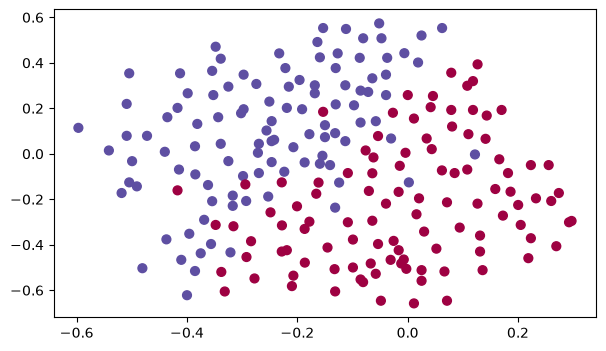

In [81]:
data = scipy.io.loadmat('data.mat')
train_X = data['X'].T
train_Y = data['y'].T
test_X = data['Xval'].T
test_Y = data['yval'].T

plt.scatter(train_X[0, :], train_X[1, :], c=train_Y, s=40, cmap=plt.cm.Spectral);

**The objective**: Correctly classify the 2D points.

**Analysis of the dataset**: This dataset is a little bit noisy, but it looks like a diagonal line separating the blue points from the red ones.

**Steps**

- First, try a non-regularized model.
- Second, try different regularized models.
- Analyze the results and choose the best models.


## 1 - Baseline model -- Non-regularized

Use the following neural network. This model can be used:
- in *regularization mode* -- by setting the `lambd` input to a non-zero value.
- in *dropout mode* -- by setting the `keep_prob` to a value less than one.

You will first try the model without any regularization. Then, you will implement:
- *L2 regularization* -- functions: "`compute_cost_with_regularization()`" and "`backward_propagation_with_regularization()`"
- *Dropout* -- functions: "`forward_propagation_with_dropout()`" and "`backward_propagation_with_dropout()`"

In each part, you will run this model with the correct inputs so that it calls the right functions.

**First thing to do:** Take a look at the code below to familiarize yourself with the model.

In [82]:
def model(X, Y, learning_rate = 0.3, num_iterations = 30000, print_cost = True, lambd = 0, keep_prob = 1):
    """
    Implements a three-layer neural network: LINEAR->RELU->LINEAR->RELU->LINEAR->SIGMOID.

    Arguments:
    X -- input data, of shape (input size, number of examples)
    Y -- true "label" vector (1 for blue dot / 0 for red dot), of shape (output size, number of examples)
    learning_rate -- learning rate of the optimization
    num_iterations -- number of iterations of the optimization loop
    print_cost -- If True, print the cost every 10000 iterations
    lambd -- regularization hyperparameter, scalar
    keep_prob - probability of keeping a neuron active during drop-out, scalar.

    Returns:
    parameters -- parameters learned by the model. They can then be used to predict.
    """

    grads = {}
    costs = []                            # to keep track of the cost
    m = X.shape[1]                        # number of examples
    layers_dims = [X.shape[0], 20, 3, 1]  # A three layer NN:
                                          #      20 neurons in the layer #1
                                          #      3 neurons in the layer #2
                                          #      1 neurons in the layer #3 (the output layer)

    # Initialize parameters dictionary.
    parameters = initialize_parameters(layers_dims)

    # Loop (gradient descent)
    for i in range(0, num_iterations):

        # Forward propagation: LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID.
        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        elif keep_prob < 1:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # Cost function
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # Backward propagation.
        assert(lambd==0 or keep_prob==1)    # In practice, it is possible to use both L2 regularization and dropout,
                                            # but this exercise will only explore one at a time
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        elif keep_prob < 1:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the loss every 10000 iterations
        if print_cost and i % 10000 == 0:
            print("Cost after iteration {}: {}".format(i, cost))
        if print_cost and i % 1000 == 0:
            costs.append(cost)

    # plot the cost
    plt.plot(costs)
    plt.ylabel('cost')
    plt.xlabel('iterations (x1,000)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()

    return parameters

Let's train the model without any regularization, and observe the accuracy on the train/test sets.


# To Do:

Train a model whithout any regularization.
Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000
Do not modify the architecture of the network (defined in layers_dims).


Using the fonction "model" defined here above.

This function return "parameters" that you can use with function "predict" to evaluate the performance of the model.

Examples of Basic calls to these functions are:
- parameters = model(X, Y)
- predictions_train = predict(Xtr, Ytr, parameters)
- predictions_test = predict(Xte, Yte, parameters)


Cost after iteration 0: 0.6557412523481002
Cost after iteration 10000: 0.16329987525724216
Cost after iteration 20000: 0.13851642423254343


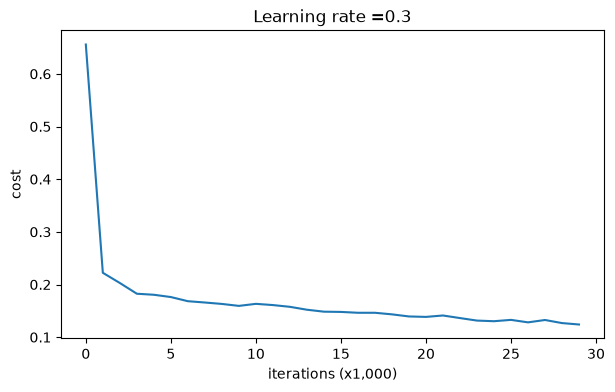

On the training set:
Accuracy: 0.9478672985781991
On the test set:
Accuracy: 0.915


In [ ]:
parameters = model(train_X, train_Y)
print ("On the training set:")parameters
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

on the training set the accuracy 0.94 and on the test it is 0.91 which is pretty close, but there is a slice difference which means that the model did overfit for a bit on the training data

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

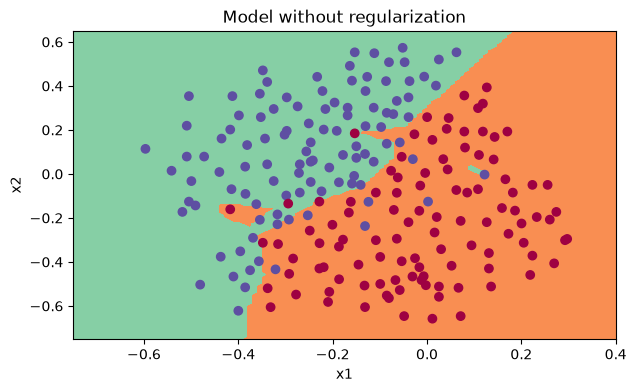

In [84]:
plt.title("Model without regularization")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

**Provide your comments on the plot above:**

Well in overall it is separating the dots well, however there are few overfitting elenments where there is a citcles around the elements 

**What do you suggest to avoid the observed phenomenon?**
We suggest adding a regularization


## 2 - L2 Regularization

One solution to avoid overfitting is **L2 regularization**.

Here are the two functions:
- The first one computes the cost considering L2 regularization.
- The second one performs back-propagation considering L2 regularization.

In [85]:
# compute_cost_with_regularization

def compute_cost_with_regularization(A3, Y, parameters, lambd):
    """
    Implement the cost function with L2 regularization. See formula (2) above.

    Arguments:
    A3 -- post-activation, output of forward propagation, of shape (output size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    parameters -- python dictionary containing parameters of the model

    Returns:
    cost - value of the regularized loss function (formula (2))
    """
    m = Y.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    W3 = parameters["W3"]

    cross_entropy_cost = compute_cost(A3, Y) # This gives you the cross-entropy part of the cost

    L2_regularization_cost = (lambd/(2*m))*(np.sum(np.square(W1))+np.sum(np.square(W2))+np.sum(np.square(W3)))

    cost = cross_entropy_cost + L2_regularization_cost

    return cost

In [86]:
def backward_propagation_with_regularization(X, Y, cache, lambd):
    """
    Implements the backward propagation of our baseline model to which we added an L2 regularization.

    Arguments:
    X -- input dataset, of shape (input size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation()
    lambd -- regularization hyperparameter, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y

    dW3 = 1./m * np.dot(dZ3, A2.T) + np.multiply(lambd/m,W3)
    db3 = 1./m * np.sum(dZ3, axis=1, keepdims = True)

    dA2 = np.dot(W3.T, dZ3)
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1./m * np.dot(dZ2, A1.T) + np.multiply(lambd/m,W2)
    db2 = 1./m * np.sum(dZ2, axis=1, keepdims = True)

    dA1 = np.dot(W2.T, dZ2)
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1./m * np.dot(dZ1, X.T) + np.multiply(lambd/m,W1)
    db1 = 1./m * np.sum(dZ1, axis=1, keepdims = True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

Let's train the  model with L2 regularization $(\lambda = 0.7)$, and observe the accuracy on the train/test sets.


# TO DO:

Train a model with L2 regularization $(\lambda = 0.7)$.
Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000 and of course $\lambda$.
Do not modify the architecture of the network (defined in layers_dims).

Use the other parameters of fonction "model". As in the previous part, this function returns "parameters" that can be used within function "predict" to evaluate the performance of the model.

Cost after iteration 0: 0.685532107323119
Cost after iteration 10000: 0.25494736065724033
Cost after iteration 20000: 0.2549977199428217


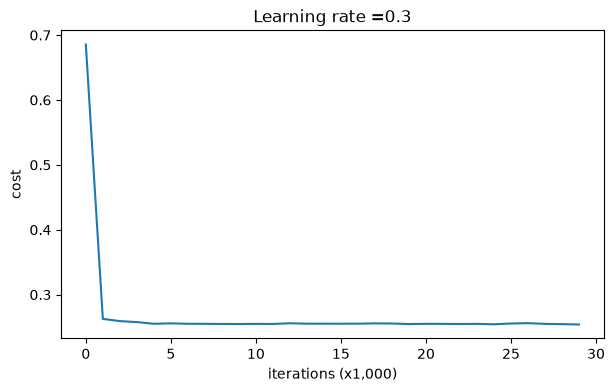

On the train set:
Accuracy: 0.9478672985781991
On the test set:
Accuracy: 0.94


In [87]:
parameters = model(train_X, train_Y, lambd = 0.5) # 0.7
print ("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

This is much better the accuracy is the same for traning and for test

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

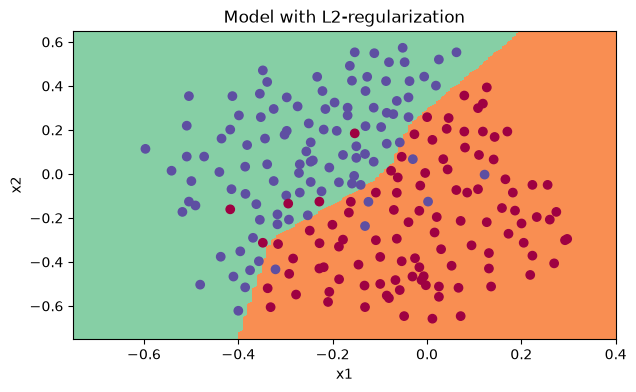

In [88]:
plt.title("Model with L2-regularization")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

**Observations**:
- The value of $\lambda$ is a hyperparameter that you can tune using a dev set.
- L2 regularization makes your decision boundary smoother. If $\lambda$ is too large, it is also possible to "oversmooth", resulting in a model with high bias.


## TO DO:

Vary the value of $\lambda$ and analyze the impact of the value of $\lambda$ on the accuracy (train and test), on the parameters $w$ (their absolute values and their variance) and on the decision boundary.

Provide the figures illustrating the boundary decision for the different values of $\lambda$. At least 3 values of $\lambda$ have to be considered. Analyze the results.

well When we increase lambda it becomes more smoother which drops the accuracy (for 0.9 it become 92%/93%)
when we decrease lambda the shape become less smoother and the accuracy increases for 0.5 94%/94% and then it will decrease again dropping the accuracy of the traning while the one of the test stay high

## 3 - Dropout

Another way to avoid overfitting is to use Dropout.

Here are the two functions that:
- Performs foward-propagation with dropout.
- Performs back-propagation with dropout.

The function `model()` will now call:
- `forward_propagation_with_dropout` instead of `forward_propagation`.
- `backward_propagation_with_dropout` instead of `backward_propagation`.

In [89]:
def forward_propagation_with_dropout(X, parameters, keep_prob = 0.5):
    """
    Implements the forward propagation: LINEAR -> RELU + DROPOUT -> LINEAR -> RELU + DROPOUT -> LINEAR -> SIGMOID.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    parameters -- python dictionary containing your parameters "W1", "b1", "W2", "b2", "W3", "b3":
                    W1 -- weight matrix of shape (20, 2)
                    b1 -- bias vector of shape (20, 1)
                    W2 -- weight matrix of shape (3, 20)
                    b2 -- bias vector of shape (3, 1)
                    W3 -- weight matrix of shape (1, 3)
                    b3 -- bias vector of shape (1, 1)
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    A3 -- last activation value, output of the forward propagation, of shape (1,1)
    cache -- tuple, information stored for computing the backward propagation
    """

    np.random.seed(1)

    # retrieve parameters
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    W3 = parameters["W3"]
    b3 = parameters["b3"]

    # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID
    Z1 = np.dot(W1, X) + b1
    A1 = relu(Z1)
    # Steps 1-4 below correspond to the Steps 1-4 described above.
    D1 = np.random.rand(A1.shape[0],A1.shape[1])                # Step 1: initialize matrix D1 = np.random.rand(..., ...)
    D1 = np.where(D1 < keep_prob, 1.0, 0.0)            # Step 2: convert entries of D1 to 0 or 1 (using keep_prob as the threshold)
    A1 = A1*D1                                         # Step 3: shut down some neurons of A1
    A1 = A1/keep_prob                                         # Step 4: scale the value of neurons that haven't been shut down
    Z2 = np.dot(W2, A1) + b2
    A2 = relu(Z2)

    D2 = np.random.rand(A2.shape[0],A2.shape[1])                  # Step 1: initialize matrix D2 = np.random.rand(..., ...)
    D2 = np.where(D2 < keep_prob, 1.0, 0.0)          # Step 2: convert entries of D2 to 0 or 1 (using keep_prob as the threshold)
    A2 = A2*D2                                        # Step 3: shut down some neurons of A2
    A2 = A2/keep_prob                                         # Step 4: scale the value of neurons that haven't been shut down

    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)

    cache = (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)

    return A3, cache

**TO DO:**

Describe with your own words the function ***forward_propagation_with_dropout***

The function `forward_propagation_with_dropout` implements the forward pass of NN while applying dropout regularization where, during training, a random subset of neurons ignored in each forward pass

In [90]:
def backward_propagation_with_dropout(X, Y, cache, keep_prob):
    """
    Implements the backward propagation of our baseline model to which we added dropout.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation_with_dropout()
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y
    dW3 = 1./m * np.dot(dZ3, A2.T)
    db3 = 1./m * np.sum(dZ3, axis=1, keepdims = True)
    dA2 = np.dot(W3.T, dZ3)

    dA2 = dA2*D2              # Step 1: Apply mask D2 to shut down the same neurons as during the forward propagation
    dA2 = dA2/keep_prob              # Step 2: Scale the value of neurons that haven't been shut down

    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1./m * np.dot(dZ2, A1.T)
    db2 = 1./m * np.sum(dZ2, axis=1, keepdims = True)

    dA1 = np.dot(W2.T, dZ2)

    dA1 = dA1*D1              # Step 1: Apply mask D1 to shut down the same neurons as during the forward propagation
    dA1 = dA1/keep_prob              # Step 2: Scale the value of neurons that haven't been shut down

    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1./m * np.dot(dZ1, X.T)
    db1 = 1./m * np.sum(dZ1, axis=1, keepdims = True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

**TO DO:**

Describe with your own words the function ***backward_propagation_with_dropout***

During the update of the weights, the function `backward_propagation_with_dropout` implements the backward pass of NN while applying dropout regularization where, during training, a random subset of neurons ignored in each backward pass so their weights are not updated. This helps to prevent overfitting by reducing the reliance on specific neurons and promoting more robust feature learning.

## TO DO
Train a model with dropout (`keep_prob = 0.86`).
This means at every iteration you shut down each neurons of layer 1 and 2 with 14% probability.

Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000 and of course `keep_prob`.

Do not modify the architecture of the network (defined in layers_dims).


Use the other parameters of fonction "model". As in previous part, this function returns "parameters" that can be used within function "predict" to evaluate the performance of the model.

Cost after iteration 0: 0.6543912405149825
Cost after iteration 10000: 0.061016986574905605
Cost after iteration 20000: 0.060582435798513114


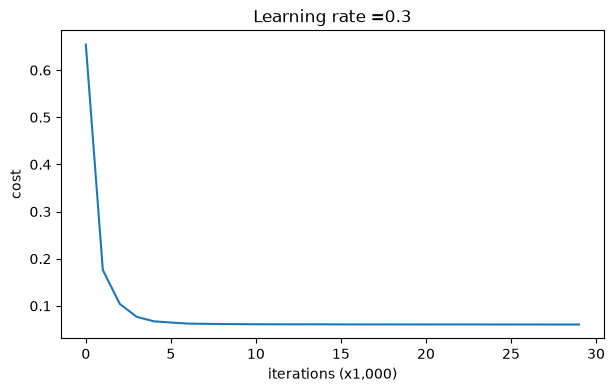

On the train set:
Accuracy: 0.9289099526066351
On the test set:
Accuracy: 0.95


In [91]:
parameters = model(train_X, train_Y, keep_prob = 0.86, learning_rate = 0.3)

print ("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

# TO DO:
Provide the report and the analysis of your experiments here:

The training accuracy is 0.92 and the test accuracy is 0.95 which is a good result and it is better than the one of the L2 regularization. The model is not overfitting and it is generalizing well on the test set

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

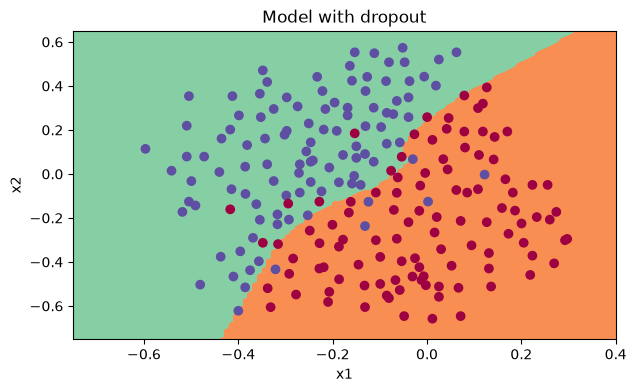

In [92]:
plt.title("Model with dropout")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

## TO DO:

Vary the value of `keep_prob` and analyse the impact of the value of $\lambda$ on the accuracy (train ans test), on the parameters $w$ and on the decision boundary.

Provide a summary of the conducted experiments and analyse the obtained results.

When we decrease the keep prob the performace of the model decreases and the accuracy drops, while when we increase it the accuracy increases and the model generalizes better on the test set. The best value for keep_prob is 0.86

## 4 - General Summary

Fill the table below with the results of performed experiments (double click on the table and introduce your numbers).

**Here are the results of our three models**:

<table>
    <tr>
        <td>
        **model**
        </td>
        <td>
        **train accuracy**
        </td>
        <td>
        **test accuracy**
        </td>
    </tr>
        <td>
        3-layer NN without regularization
        </td>
        <td>
        0.94
        </td>
        <td>
        0.91
        </td>
    <tr>
        <td>
        3-layer NN with L2-regularization
        </td>
        <td>
        0.94
        </td>
        <td>
        0.94
        </td>
    </tr>
    <tr>
        <td>
        3-layer NN with dropout
        </td>
        <td>
        0.92
        </td>
        <td>
        0.95
        </td>
    </tr>
</table>

Note that regularization hurts training set performance! This is because it limits the ability of the network to overfit to the training set. But since it ultimately gives better test accuracy, it is helping your system.

## 5 - Modification of the network architecture

Now, you have to modify the number of neurons in the second and third layers (using "layers_dims" in function "model") and try to obtain better results for the three configuration (without regularisation, using L2-regularisation, using dropout).

Obtained results must be analyzed and presented in a table (as in the previous cell).



**Take away**:
- Regularization will help you reduce overfitting.
- Regularization will drive your weights to lower values.
- L2 regularization and Dropout are two very effective regularization techniques.


_______________________

In [93]:
def model_custom(X, Y, layers_dims, learning_rate = 0.3, num_iterations = 30000, print_cost = False, lambd = 0, keep_prob = 1):
    """
    Implements a three-layer neural network with flexible layer dimensions:
    LINEAR->RELU->LINEAR->RELU->LINEAR->SIGMOID.
    """
    grads = {}
    costs = []
    m = X.shape[1]

    parameters = initialize_parameters(layers_dims)

    for i in range(0, num_iterations):

        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        elif keep_prob < 1:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # Cost function
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # Backward propagation
        assert(lambd == 0 or keep_prob == 1)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        elif keep_prob < 1:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        # Update parameters
        parameters = update_parameters(parameters, grads, learning_rate)

        if print_cost and i % 10000 == 0:
            print(f"Cost after iteration {i}: {cost}")
        if i % 1000 == 0:
            costs.append(cost)

    return parameters

In [94]:
import copy

def plot_weight_histograms(initial_params, trained_params, title="Weight Distributions (Before vs. After)"):
    """
    Plots overlaid histograms comparing initial weights vs. trained weights for W1, W2, and W3.
    """
    layers = [('W1', 'Layer 1 (W1)'), ('W2', 'Layer 2 (W2)'), ('W3', 'Layer 3 (W3)')]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    for idx, (w_key, label) in enumerate(layers):
        w_init = initial_params[w_key].flatten()
        w_final = trained_params[w_key].flatten()
        
        ax = axes[idx]
        ax.hist(w_init, bins=25, alpha=0.5, label=f'Before (std: {np.std(w_init):.3f})', color='royalblue', edgecolor='black')
        ax.hist(w_final, bins=25, alpha=0.6, label=f'After (std: {np.std(w_final):.3f})', color='crimson', edgecolor='black')
        
        ax.set_title(f"{label}\nFinal Mean: {np.mean(w_final):.4f} | Std: {np.std(w_final):.4f}")
        ax.set_xlabel("Weight Value")
        ax.set_ylabel("Count")
        ax.legend(frameon=True, fontsize=8)
        ax.grid(True, linestyle="--", alpha=0.3)
        
    plt.suptitle(title, y=1.03, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

def train_and_capture(X, Y, layers_dims, learning_rate=0.3, num_iterations=30000, lambd=0, keep_prob=1):
    """
    Trains the model without calling plt.show(), capturing weights before and after.
    """
    np.random.seed(3)
    init_params = initialize_parameters(layers_dims)
    initial_snapshot = {k: v.copy() for k, v in init_params.items()}
    parameters = {k: v.copy() for k, v in init_params.items()}

    for i in range(num_iterations):
        # Forward pass
        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        else:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # Cost computation
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # Backward pass
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        elif keep_prob < 1:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        parameters = update_parameters(parameters, grads, learning_rate)

    return initial_snapshot, parameters

<>:29: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:31: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:37: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:29: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:31: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:37: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/ipykernel_525043/2600463889.py:29: SyntaxWarning: "\l" is an invalid es

Training L2 models...
Accuracy: 0.9478672985781991
Accuracy: 0.915
Accuracy: 0.9383886255924171
Accuracy: 0.95
Accuracy: 0.9478672985781991
Accuracy: 0.94
Accuracy: 0.9241706161137441
Accuracy: 0.93
Training complete.


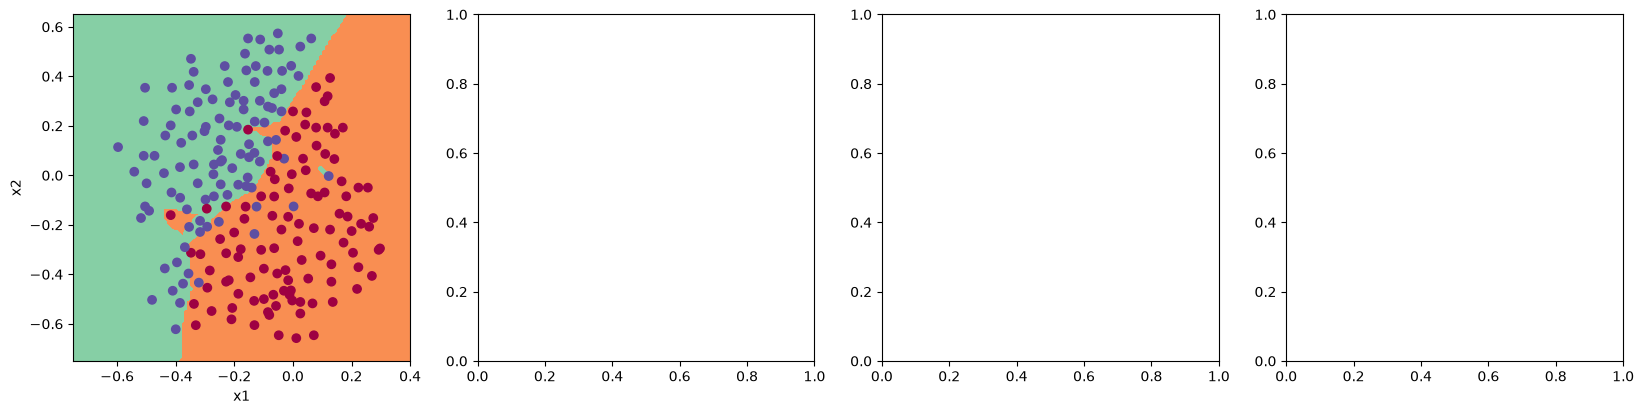

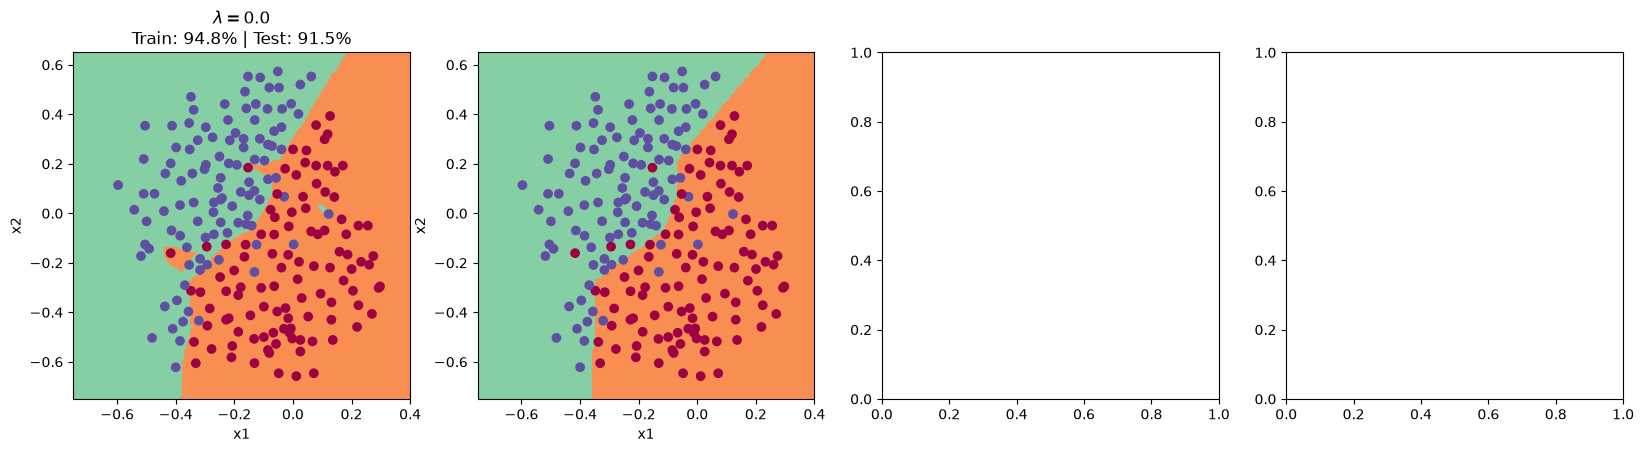

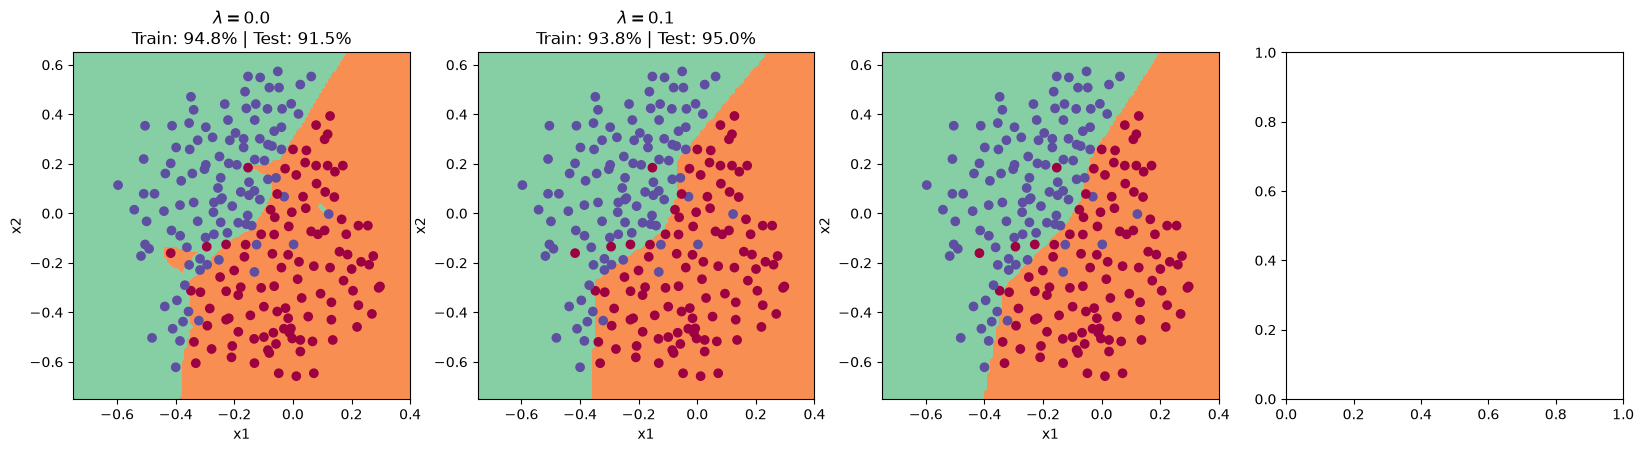

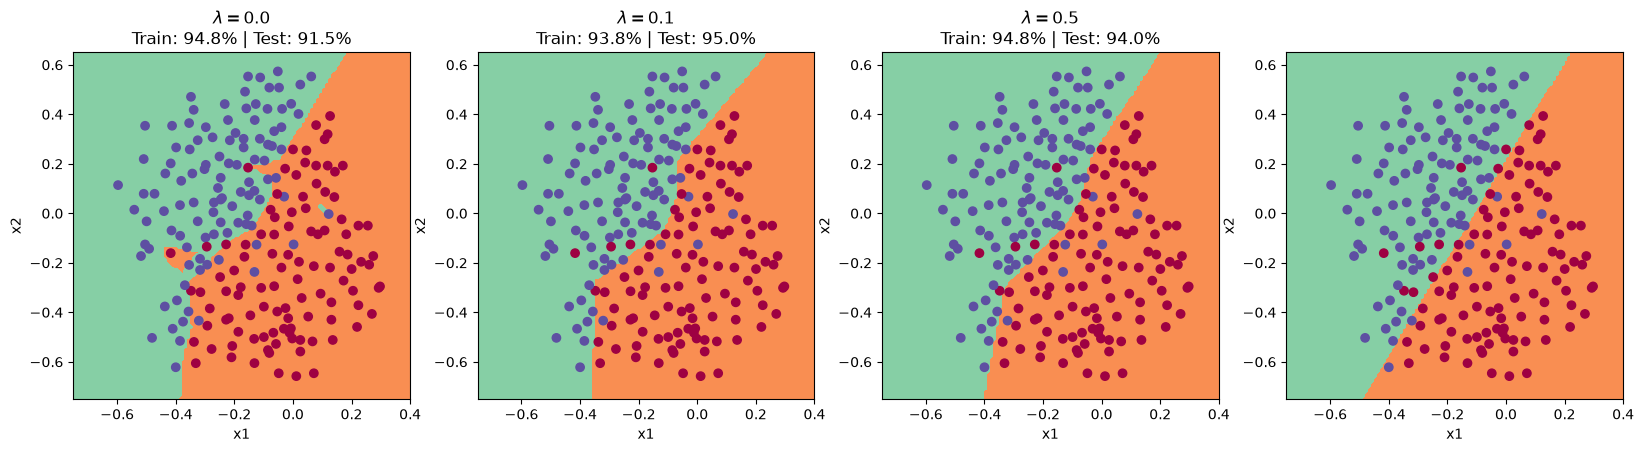

<Figure size 700x400 with 0 Axes>

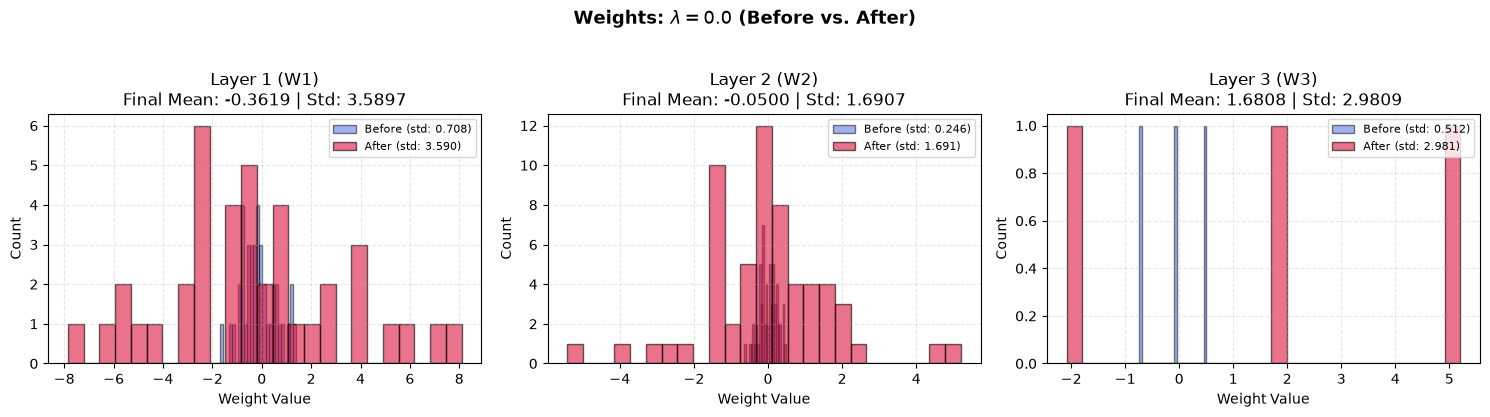

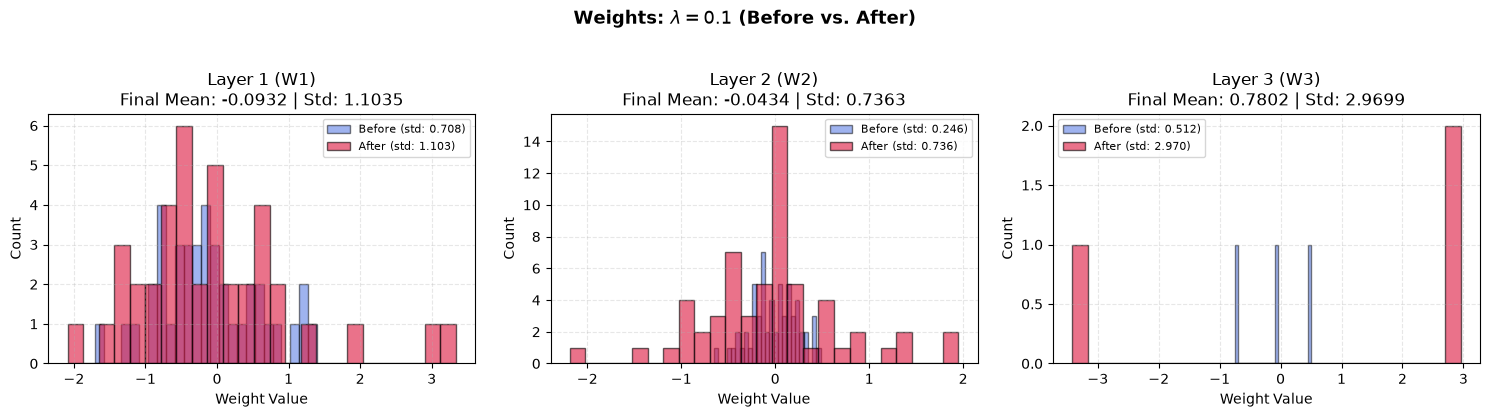

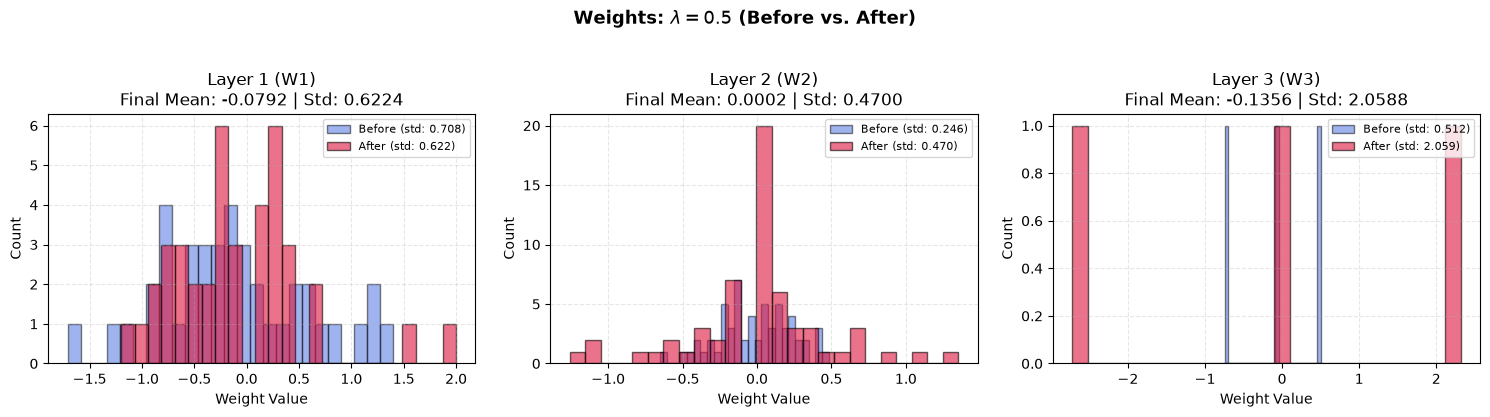

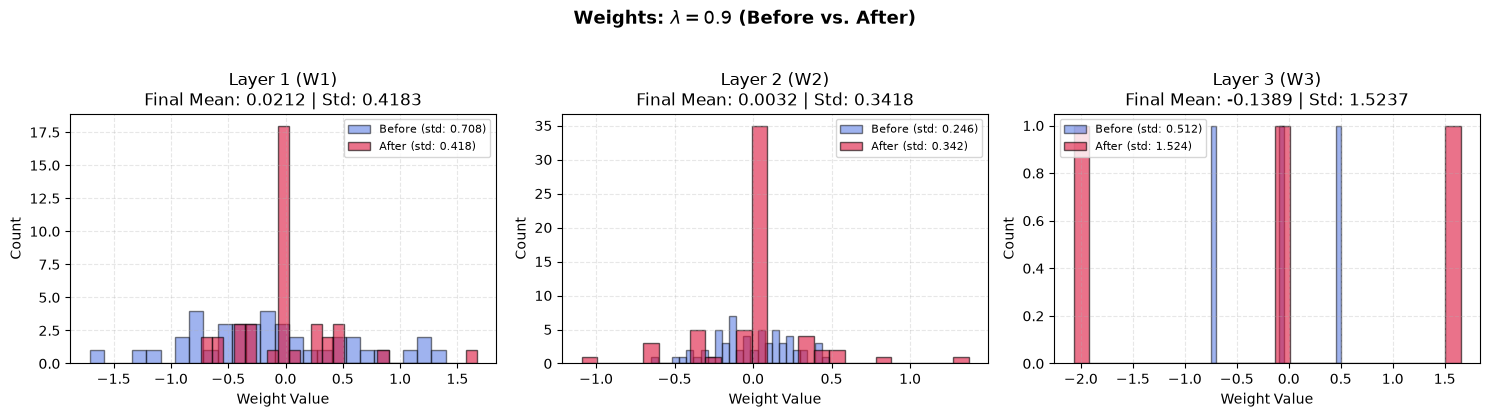

In [95]:
# %% [code]
lambd_values = [0.0, 0.1, 0.5, 0.9]
layers_dims = [train_X.shape[0], 20, 3, 1]

l2_results = []
print("Training L2 models...")
for lmb in lambd_values:
    w_init, w_final = train_and_capture(train_X, train_Y, layers_dims, 
                                        learning_rate=0.3, num_iterations=30000, 
                                        lambd=lmb, keep_prob=1)
    train_acc = np.mean(predict(train_X, train_Y, w_final) == train_Y) * 100
    test_acc = np.mean(predict(test_X, test_Y, w_final) == test_Y) * 100
    l2_results.append({
        'lambd': lmb,
        'w_init': w_init,
        'w_final': w_final,
        'train_acc': train_acc,
        'test_acc': test_acc
    })
print("Training complete.")

fig, axes = plt.subplots(1, len(lambd_values), figsize=(20, 4.5))

for idx, res in enumerate(l2_results):
    plt.sca(axes[idx])
    axes[idx].set_xlim([-0.75, 0.40])
    axes[idx].set_ylim([-0.75, 0.65])
    plot_decision_boundary(lambda x: predict_dec(res['w_final'], x.T), train_X, train_Y)
    axes[idx].set_title(f"$\lambda = {res['lambd']}$\nTrain: {res['train_acc']:.1f}% | Test: {res['test_acc']:.1f}%")

plt.suptitle("L2 Regularization: Decision Boundaries Across $\lambda$", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

for res in l2_results:
    plot_weight_histograms(res['w_init'], res['w_final'], 
                           title=f"Weights: $\lambda = {res['lambd']}$ (Before vs. After)")

Training Dropout models...
Accuracy: 0.909952606635071
Accuracy: 0.935
Accuracy: 0.9146919431279621
Accuracy: 0.92
Accuracy: 0.9289099526066351
Accuracy: 0.95
Accuracy: 0.9478672985781991
Accuracy: 0.915
Training complete.


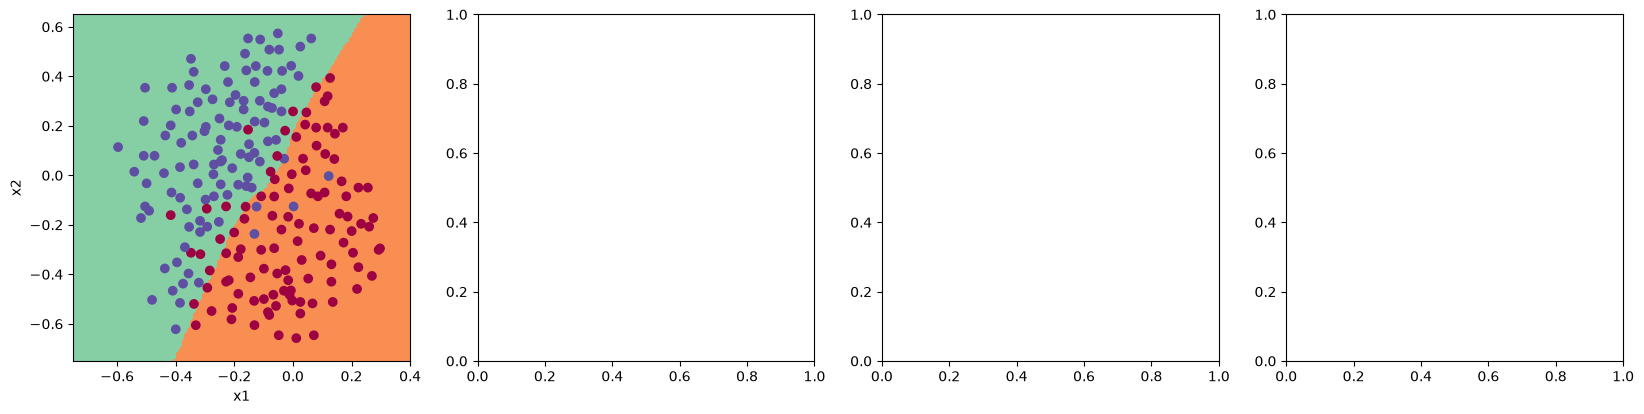

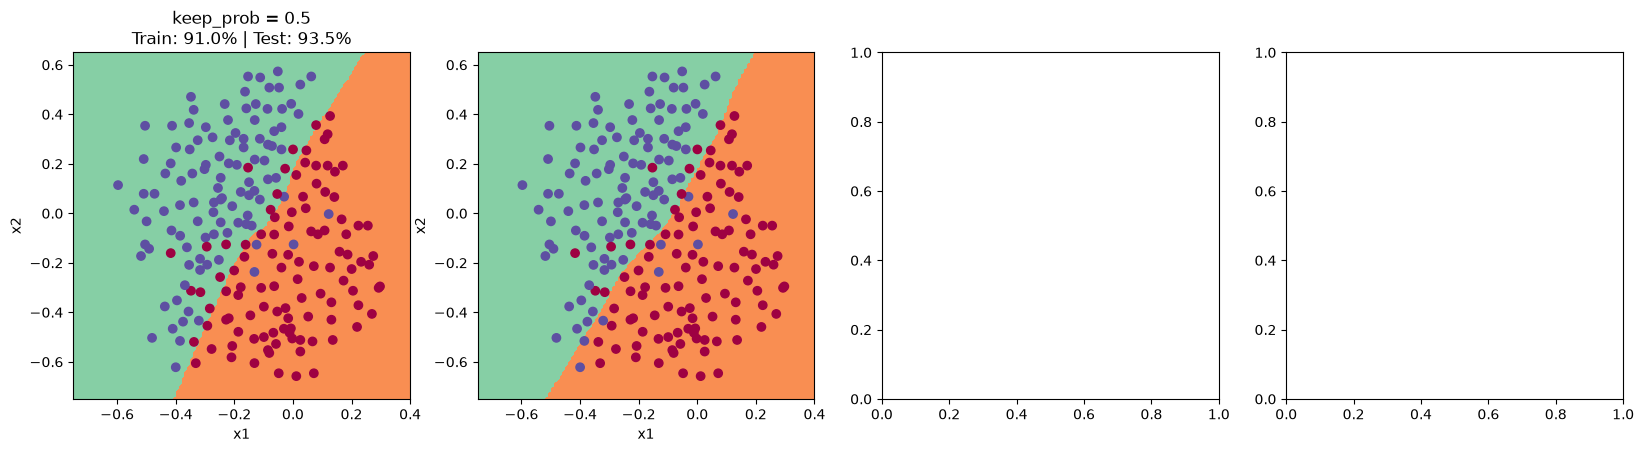

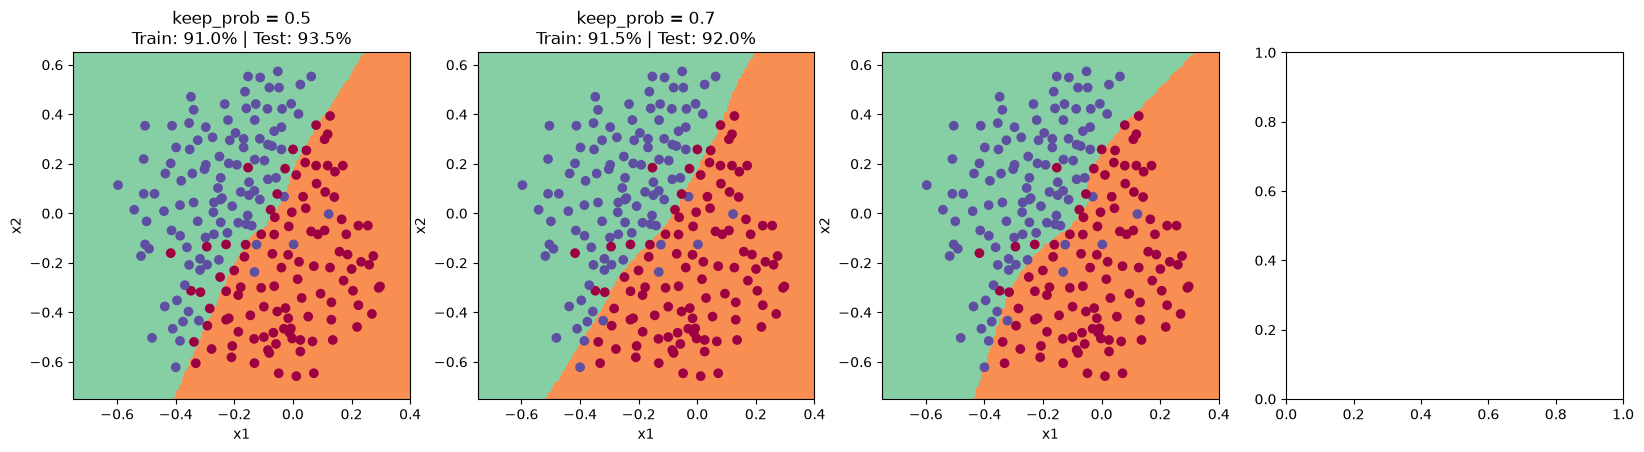

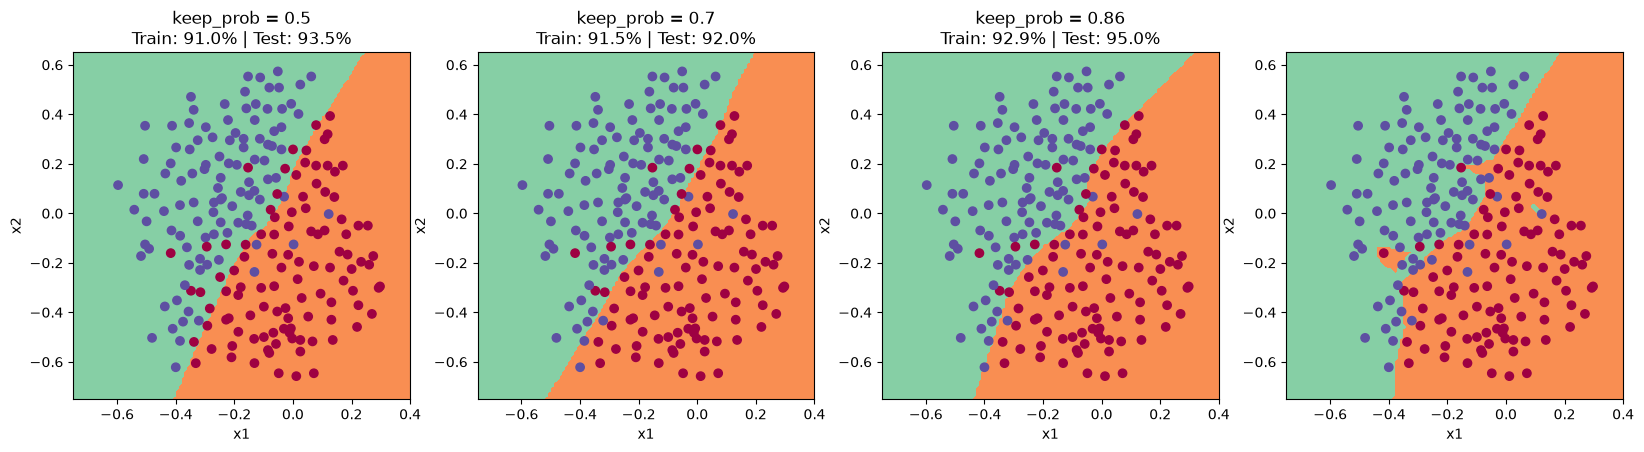

<Figure size 700x400 with 0 Axes>

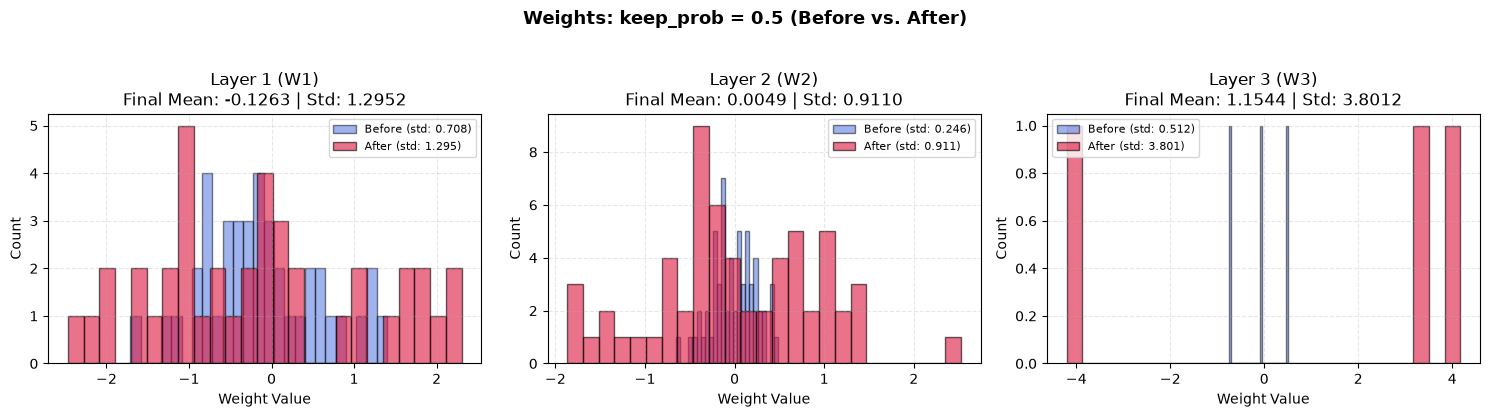

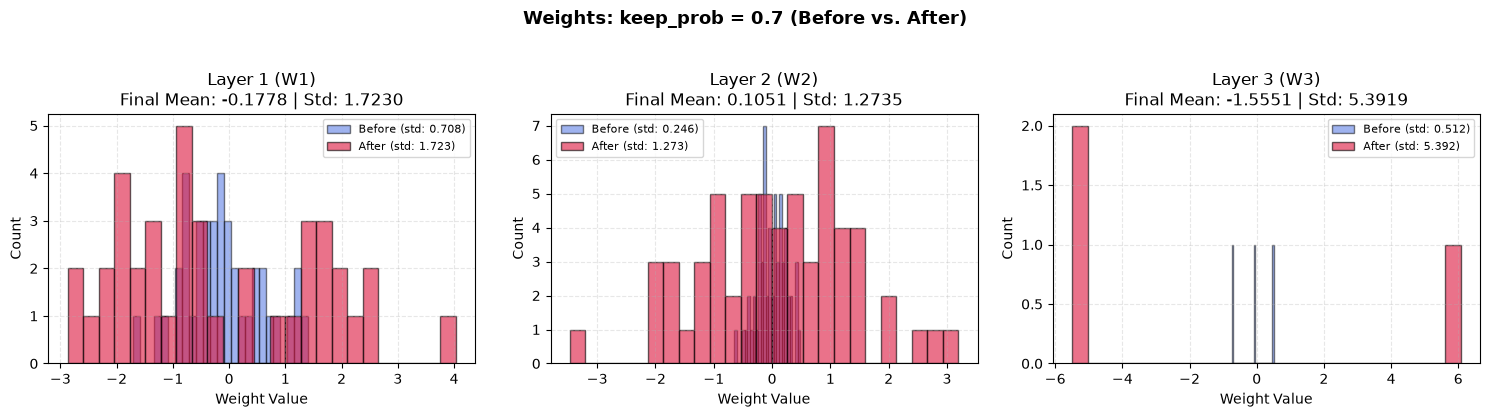

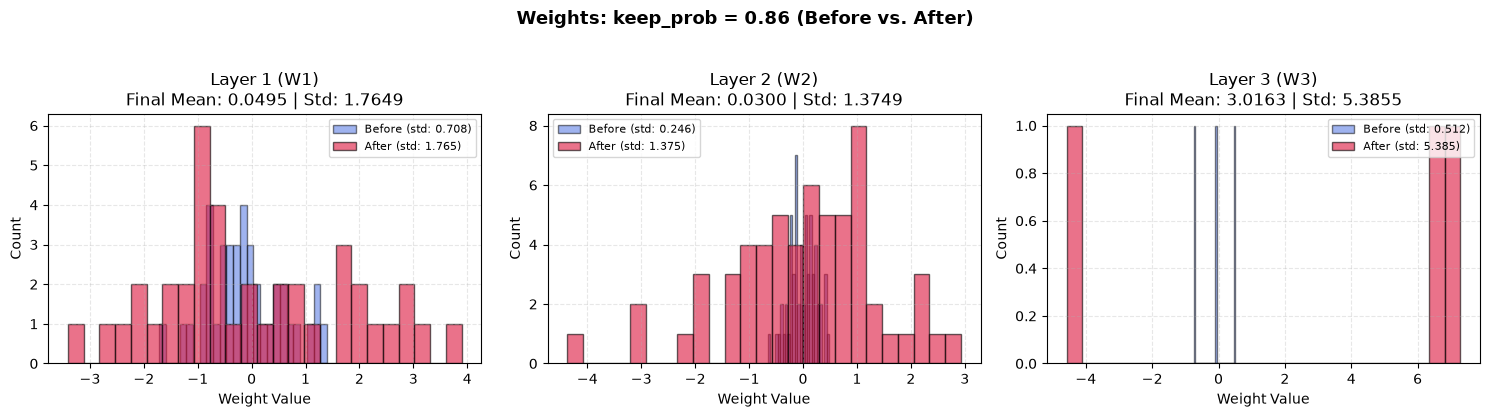

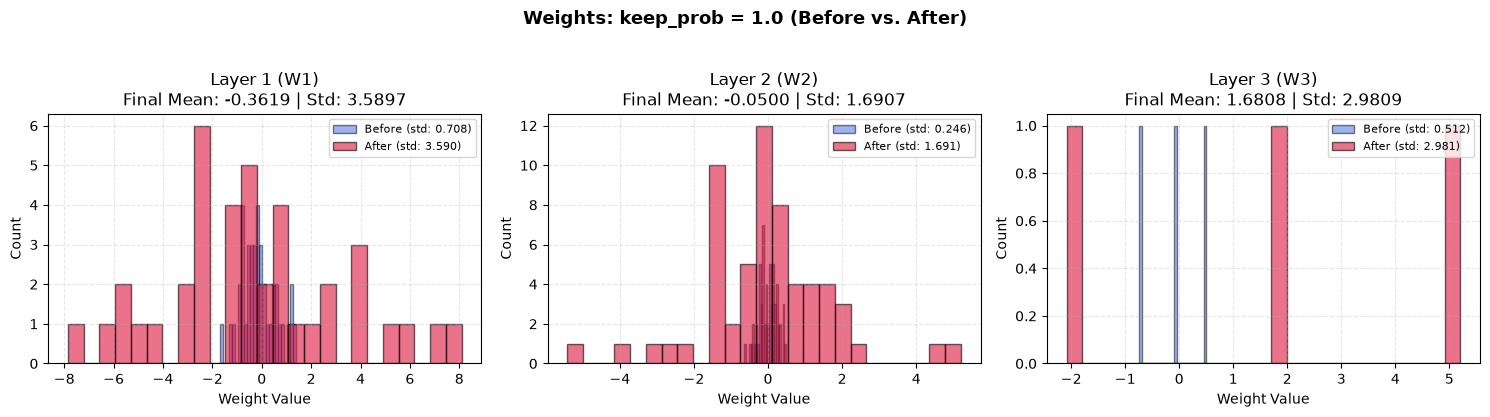

In [96]:
# %% [code]
keep_probs = [0.5, 0.7, 0.86, 1.0]

dropout_results = []
print("Training Dropout models...")
for kp in keep_probs:
    w_init, w_final = train_and_capture(train_X, train_Y, layers_dims, 
                                        learning_rate=0.3, num_iterations=30000, 
                                        lambd=0, keep_prob=kp)
    train_acc = np.mean(predict(train_X, train_Y, w_final) == train_Y) * 100
    test_acc = np.mean(predict(test_X, test_Y, w_final) == test_Y) * 100
    dropout_results.append({
        'keep_prob': kp,
        'w_init': w_init,
        'w_final': w_final,
        'train_acc': train_acc,
        'test_acc': test_acc
    })
print("Training complete.")

fig, axes = plt.subplots(1, len(keep_probs), figsize=(20, 4.5))

for idx, res in enumerate(dropout_results):
    plt.sca(axes[idx])
    axes[idx].set_xlim([-0.75, 0.40])
    axes[idx].set_ylim([-0.75, 0.65])
    plot_decision_boundary(lambda x: predict_dec(res['w_final'], x.T), train_X, train_Y)
    axes[idx].set_title(f"keep_prob = {res['keep_prob']}\nTrain: {res['train_acc']:.1f}% | Test: {res['test_acc']:.1f}%")

plt.suptitle("Dropout: Decision Boundaries Across keep_prob", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show() 

for res in dropout_results:
    plot_weight_histograms(res['w_init'], res['w_final'], 
                           title=f"Weights: keep_prob = {res['keep_prob']} (Before vs. After)")